# Scan lenses: F-theta and telecentric lenses behind two galvo mirrors

A laser marking or processing head moves a focused spot over the workpiece
with two galvanometer mirrors and a **scan lens** behind them: the mirrors
turn a collimated beam, the lens focuses it onto a flat field. The scanner
sits in the entrance pupil, in front of the lens, and the object is at
infinity: the field of the lens is the scan angle θ. This notebook designs
the two classical kinds of scan lens with the damped least squares
optimizer of notebook [58 (lens optimization)](58_lens_optimization.ipynb),
then puts the real two-mirror scanner of notebook
[132 (beam scanning)](132_beam_scanning.ipynb) in front of them and
corrects the scan with a lookup table, as scanner controllers do. It
extends the processing head of notebook
[48 (laser head DOE)](48_laser_head_doe.ipynb), whose focusing singlet
looks at a fixed field.

1. Image height laws: $f\tan\theta$, $f\theta$ and the spot size
2. An F-theta lens optimized with DLS (f = 160 mm, ±18°, 10 mm beam, 1064 nm)
3. A telecentric scan lens (f = 100 mm, ±12°)
4. Two galvos in front of the lens: the bow of the scan lines
5. Telecentricity with two mirrors: where to put the pupil
6. Correction by a lookup table

Tools: `scan_lenses` (`ftheta_error()`, `image_telecentricity()`,
`galvo_spots()`, `invert_scan()`, `CorrectionTable`), the operand
`lens_optimization.ftheta()` and `lidar.galvo_beam()`, the beam behind the
mirrors that `lidar.galvo_xy()` also uses.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import glasses
from pyoptics import lens_optimization as lo
from pyoptics import lidar
from pyoptics import raytrace as rt
from pyoptics import scan_lenses as sl

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()

WL = 1064e-6                 # mm, Nd:YAG / Yb fibre laser
SF6 = glasses.get("N-SF6")
BLUE, ORANGE, GREEN, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b", "#888888"

## 1. Image height laws

An ordinary, distortion free lens images the direction θ to the height
$h = f\tan\theta$. Behind a scanner whose mirror turns at a constant
angular speed, the spot would then speed up towards the edge of the field,
and the scanner control would have to correct for $\tan$. An **F-theta
lens** has just the right barrel distortion to give $h = f\theta$: the
spot position is linear in the mirror angle, and a constant mirror speed
writes a constant line speed (constant dose per unit length in marking).
The barrel distortion against $f\tan\theta$ is $\theta/\tan\theta - 1$,
−1 % at 10° and −3.3 % at 18°. (The aplanatic $f\sin\theta$ of a lens
that obeys the sine condition, as in notebook
[102 (sine and Herschel conditions)](102_sine_herschel_lagrange.ipynb),
bends the other way.)

The spot size is set by the beam: a Gaussian beam of 1/e² diameter D
focused with f has the waist $w_0 = 2\lambda f/(\pi D)$, 11 µm for a
10 mm beam at f = 160 mm and 1064 nm. A good scan lens keeps its
aberrations below that over the whole field; the number of spots across
the scan, $2f\theta_\mathrm{max}/2w_0$, is the invariant of notebook
[132 (beam scanning)](132_beam_scanning.ipynb), which no lens can
improve.

10°: f tan θ - f θ = 0.29 mm (1.03 %)
18°: f tan θ - f θ = 1.72 mm (3.43 %)
Gaussian focus: w0 = 10.8 um (1/e^2 radius), Airy radius of a uniform beam 20.8 um
resolvable spots over ±18°: 4638 per line


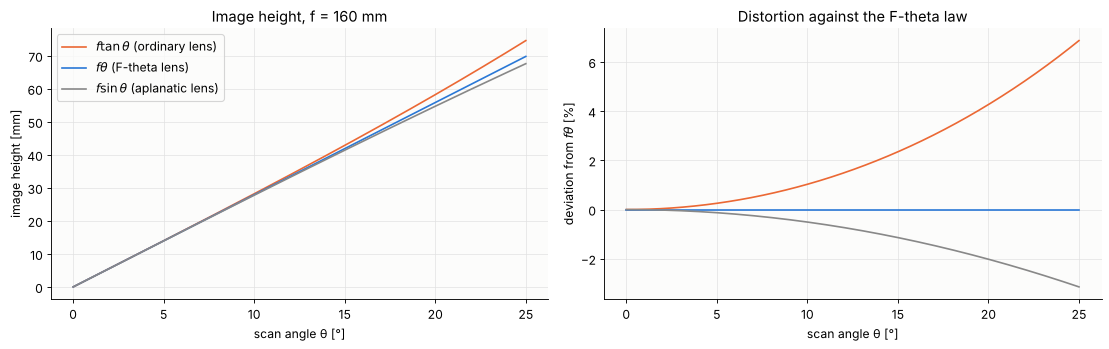

In [2]:
F, D_BEAM = 160.0, 10.0
theta = np.radians(np.linspace(0.01, 25, 200))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for h, name, col in [(F*np.tan(theta), r"$f\tan\theta$ (ordinary lens)", ORANGE),
                     (F*theta, r"$f\theta$ (F-theta lens)", BLUE),
                     (F*np.sin(theta), r"$f\sin\theta$ (aplanatic lens)", GREY)]:
    ax1.plot(np.degrees(theta), h, color=col, label=name)
    ax2.plot(np.degrees(theta), 100*(h/(F*theta) - 1), color=col, label=name)
ax1.set_xlabel("scan angle θ [°]")
ax1.set_ylabel("image height [mm]")
ax1.set_title(f"Image height, f = {F:.0f} mm")
ax1.legend()
ax2.set_xlabel("scan angle θ [°]")
ax2.set_ylabel(r"deviation from $f\theta$ [%]")
ax2.set_title("Distortion against the F-theta law")
fig.tight_layout()
for deg in (10, 18):
    t = np.radians(deg)
    print(f"{deg:2d}°: f tan θ - f θ = {F*(np.tan(t) - t):.2f} mm "
          f"({100*(np.tan(t)/t - 1):.2f} %)")
w0 = 2*WL*F/(np.pi*D_BEAM)       # Gaussian waist for a 1/e^2 beam diameter D
airy = 1.22*WL*F/D_BEAM
print(f"Gaussian focus: w0 = {w0*1e3:.1f} um (1/e^2 radius), Airy radius of a "
      f"uniform beam {airy*1e3:.1f} um")
print(f"resolvable spots over ±18°: {2*F*np.radians(18)/(2*w0):.0f} per line")

## 2. An F-theta lens optimized with damped least squares

The classical F-theta lens (Smith, *Modern Lens Design*) is a strong
negative lens close to the scanner followed by two positive lenses: the
negative lens flattens the field (its Petzval contribution cancels much of
the positive ones), and the large stop distance in front of the positive
lenses produces the barrel distortion. The start below is crude, a
concave-plano lens and two singlets, all N-SF6 (a high index helps with
the Petzval sum; high power heads use fused silica at the price of an
extra element).

- **Solve:** the curvature of the last surface holds f = 160 mm
  (`solve_curvature_for_efl()`).
- **Operands:** the RMS spot radius at five fields (`spot_rms()`,
  tolerance 1 µm), and the F-theta law at five fields
  (`lo.ftheta(F)`, chief ray height minus f·θ, tolerance 1 µm).
- **Variables:** five curvatures, the centre thicknesses and air spaces,
  and the image distance (the best flat field, not the paraxial focus).
- **Constraints:** edge thicknesses ≥ 1.5 mm, centre thicknesses between 3
  and 25 mm.

The scanner pupil is the first surface, so the paraxial entrance pupil is
the real stop and the rays need no aiming (`ray_aiming=False`, several
times faster).

In [3]:
FIELD_FT = np.radians(18.0)


def ftheta_start():
    """Scanner pupil 30 mm in front of a strong negative lens and two
    positive lenses, all N-SF6."""
    S = [rt.Surface(np.inf, 30.0, semi_diameter=D_BEAM/2, label="scanner"),
         rt.Surface(-40.0, 5.0, material=SF6), rt.Surface(np.inf, 10.0, n_after=1.0),
         rt.Surface(-400.0, 15.0, material=SF6), rt.Surface(-60.0, 1.0, n_after=1.0),
         rt.Surface(400.0, 12.0, material=SF6), rt.Surface(-120.0, 180.0, n_after=1.0)]
    return rt.System(S, 0, WL, field_angle=FIELD_FT, entrance_pupil_radius=D_BEAM/2,
                     ray_aiming=False)


LENSES_FT = (1, 3, 5)
fields = (0.0, 0.5, 0.7, 0.85, 1.0)
operands_ft = [lo.spot_rms(fields=fields, tolerance=1e-3),
               lo.ftheta(F, fields=(0.3, 0.5, 0.7, 0.85, 1.0), tolerance=1e-3)]
variables_ft = [lo.Curvature(i) for i in (1, 2, 3, 4, 5)] + \
    [lo.Thickness(i, (1.0, None)) for i in (1, 2, 3, 4, 5)] + [lo.Thickness(6)]
constraints_ft = [lo.Constraint(lo.edge_thickness(i), lower=1.5, tolerance=0.01, name=f"edge {i}")
                  for i in LENSES_FT]
constraints_ft += [lo.Constraint(lo.center_thickness(i), lower=3.0, upper=25.0, tolerance=0.01,
                                 name=f"centre {i}") for i in LENSES_FT]
opt_ft = lo.DampedLeastSquares(ftheta_start(), variables_ft, operands_ft, constraints_ft,
                               solves=[lo.solve_curvature_for_efl(6, F)])
ft_start = opt_ft.system.copy()
merit0 = opt_ft.merit()
t0 = time.time()
res_ft = opt_ft.run(max_iterations=300)
ftheta_lens = res_ft.system
print(f"{res_ft.message} after {len(res_ft.history) - 1} iterations, merit {merit0:.4g} -> "
      f"{res_ft.merit:.4g} ({time.time() - t0:.0f} s)")
print(ftheta_lens)
p = ftheta_lens.paraxial()
print(f"efl {p.efl:.3f} mm, F/{p.f_number:.1f}, back focus {ftheta_lens.surfaces[-1].thickness:.1f} mm")

maximum number of iterations after 300 iterations, merit 1.157e+08 -> 1419 (17 s)
System(wavelength=0.001064, stop_index=0, object_distance=inf, max_field=0.3141592653589793)
   0* Surface(R=inf, thickness=30.0, n_after=None, material=None, conic=0.0, aspheric=(), semi_diameter=5.0) n'=1.000000
   1  Surface(R=-45.749587598302575, thickness=3.0, n_after=None, material=Glass('N-SF6', SCHOTT, n_d=1.80518, V_d=25.36), conic=0.0, aspheric=(), semi_diameter=None) n'=1.773295
   2  Surface(R=-309.92553756430107, thickness=7.721987704232024, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=None) n'=1.000000
   3  Surface(R=-243.25731506398967, thickness=11.564147343216588, n_after=None, material=Glass('N-SF6', SCHOTT, n_d=1.80518, V_d=25.36), conic=0.0, aspheric=(), semi_diameter=None) n'=1.773295
   4  Surface(R=-54.94456774828573, thickness=1.0, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=None) n'=1.000000
   5  Surface(R=1379.5877361460234, thickness=

The optimizer bends the negative lens into a meniscus concave to the
scanner, and moves most of the power into the second lens. The rays of the
start meet the image plane in blurred bundles at heights near $f\tan\theta$;
the optimized lens lands them sharply at $f\theta$:

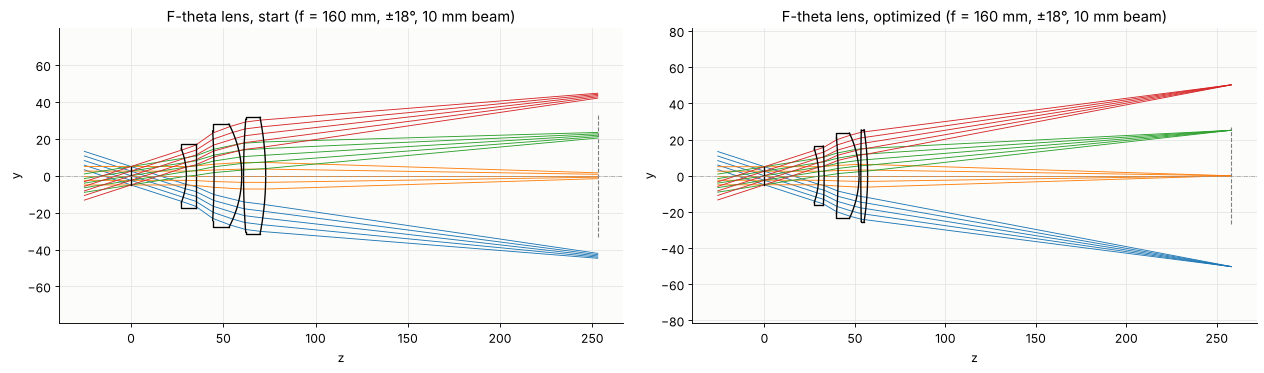

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, s, title in [(axes[0], ft_start, "start"), (axes[1], ftheta_lens, "optimized")]:
    s.draw(ax, fields=[-FIELD_FT, 0.0, 0.5*FIELD_FT, FIELD_FT], n_rays=5)
    ax.set_title(f"F-theta lens, {title} (f = 160 mm, ±18°, 10 mm beam)")
    ax.set_aspect("equal")
fig.tight_layout()

Over the 100 mm scan the RMS spot radius grows from 12 µm on axis to
23 µm at 18°, about the Airy radius of the F/16 beam (21 µm). The lens is
diffraction limited by Maréchal's criterion (0.07 waves RMS) out to 10.5°
and reaches 0.15 waves at 18°, where a fourth lens or an asphere would
help. The image height follows $f\theta$ within 8 µm, against 1.7 mm for
an undistorted lens.
The start, divided by 100 in the plot, was far off both.

The chief ray still meets the workpiece at 9° at the edge of the field:
the F-theta lens is not telecentric. A workpiece 1 mm out of the focal
plane shifts the spot by 0.16 mm there, a hole drilled at the edge is
oblique, and the spot becomes elliptical.

spot RMS 11.5 to 23.3 um, wavefront 0.145 waves max, |h - f theta| < 7.8 um over the 100.5 mm scan
chief ray angle at the workpiece at 18°: 9.0°


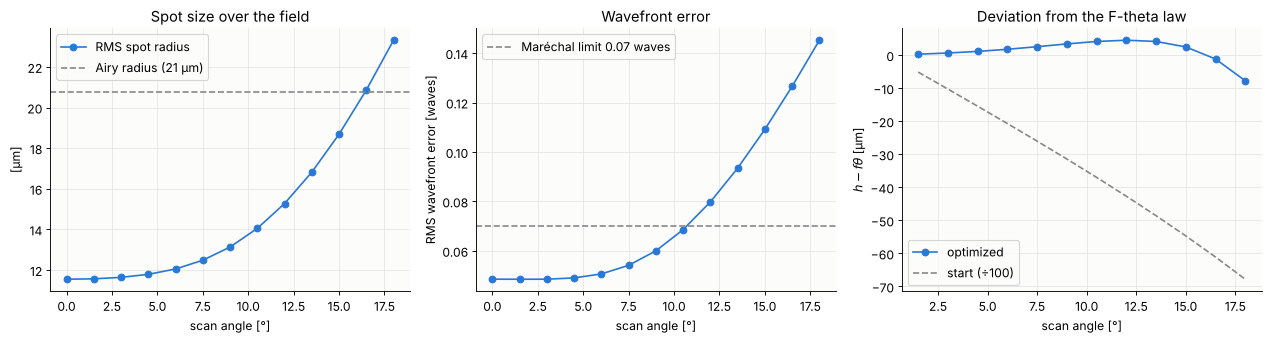

In [5]:
fr = np.linspace(0, 1, 13)
th = fr*FIELD_FT


def field_curves(s, th):
    rms = np.array([s.spot_diagram(t, N=21).rms for t in th])
    opd = np.array([s.rms_opd(t, N=32) for t in th])
    return rms, opd


rms_ft, opd_ft = field_curves(ftheta_lens, th)
err_ft = sl.ftheta_error(ftheta_lens, th[1:], F)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].plot(np.degrees(th), rms_ft*1e3, "o-", color=BLUE, label="RMS spot radius")
axes[0].axhline(airy*1e3, color=GREY, ls="--", label=f"Airy radius ({airy*1e3:.0f} µm)")
axes[0].set_ylabel("[µm]")
axes[0].set_title("Spot size over the field")
axes[0].legend()
axes[1].plot(np.degrees(th), opd_ft, "o-", color=BLUE)
axes[1].axhline(0.07, color=GREY, ls="--", label="Maréchal limit 0.07 waves")
axes[1].set_ylabel("RMS wavefront error [waves]")
axes[1].set_title("Wavefront error")
axes[1].legend()
axes[2].plot(np.degrees(th[1:]), err_ft*1e3, "o-", color=BLUE, label="optimized")
axes[2].plot(np.degrees(th[1:]), sl.ftheta_error(ft_start, th[1:], F)*1e3/100, "--", color=GREY,
             label="start (÷100)")
axes[2].set_ylabel(r"$h - f\theta$ [µm]")
axes[2].set_title("Deviation from the F-theta law")
axes[2].legend()
for ax in axes:
    ax.set_xlabel("scan angle [°]")
fig.tight_layout()
print(f"spot RMS {rms_ft.min()*1e3:.1f} to {rms_ft.max()*1e3:.1f} um, wavefront "
      f"{opd_ft.max():.3f} waves max, |h - f theta| < {np.max(np.abs(err_ft))*1e3:.1f} um "
      f"over the {2*F*FIELD_FT:.1f} mm scan")
print(f"chief ray angle at the workpiece at 18°: "
      f"{np.degrees(sl.image_telecentricity(ftheta_lens, FIELD_FT)[0]):.1f}°")

## 3. A telecentric scan lens

A lens is image space telecentric when its entrance pupil lies in its
front focal plane: every chief ray then leaves parallel to the axis. For a
scan lens this means that the scanner sits a focal length in front of the
lens (in front of its front principal plane), and that the last lens is
larger than the scan field. Telecentric scan lenses are used for drilling
(holes normal to the surface), for thick or uneven workpieces and in
scanning microscopes.

The optimization is that of section 2 with a third operand, the image
space chief ray slopes (`lo.image_telecentricity()`, tolerance 0.2 mrad),
and the distance of the scanner from the first lens as a variable. Four
N-SF6 lenses, f = 100 mm, F/10, ±12° (a ±21 mm field):

In [6]:
F_TC, FIELD_TC = 100.0, np.radians(12.0)


def telecentric_start():
    S = [rt.Surface(np.inf, 90.0, semi_diameter=D_BEAM/2, label="scanner"),
         rt.Surface(-60.0, 8.0, material=SF6), rt.Surface(-80.0, 2.0, n_after=1.0),
         rt.Surface(-300.0, 15.0, material=SF6), rt.Surface(-80.0, 1.0, n_after=1.0),
         rt.Surface(300.0, 15.0, material=SF6), rt.Surface(-200.0, 1.0, n_after=1.0),
         rt.Surface(120.0, 12.0, material=SF6), rt.Surface(500.0, 70.0, n_after=1.0)]
    return rt.System(S, 0, WL, field_angle=FIELD_TC, entrance_pupil_radius=D_BEAM/2,
                     ray_aiming=False)


LENSES_TC = (1, 3, 5, 7)
operands_tc = [lo.spot_rms(fields=fields, tolerance=1e-3),
               lo.ftheta(F_TC, fields=(0.3, 0.5, 0.7, 0.85, 1.0), tolerance=1e-3),
               lo.image_telecentricity(fields=(0.5, 0.7, 1.0), tolerance=2e-4)]
variables_tc = [lo.Curvature(i) for i in range(1, 8)] + \
    [lo.Thickness(i, (1.0, None)) for i in range(0, 8)] + [lo.Thickness(8)]
constraints_tc = [lo.Constraint(lo.edge_thickness(i), lower=1.5, tolerance=0.01, name=f"edge {i}")
                  for i in LENSES_TC]
constraints_tc += [lo.Constraint(lo.center_thickness(i), lower=3.0, upper=25.0, tolerance=0.01,
                                 name=f"centre {i}") for i in LENSES_TC]
opt_tc = lo.DampedLeastSquares(telecentric_start(), variables_tc, operands_tc, constraints_tc,
                               solves=[lo.solve_curvature_for_efl(8, F_TC)])
tc_start = opt_tc.system.copy()
t0 = time.time()
res_tc = opt_tc.run(max_iterations=250)
telecentric_lens = res_tc.system
print(f"{res_tc.message} after {len(res_tc.history) - 1} iterations ({time.time() - t0:.0f} s)")
print(telecentric_lens)
p = telecentric_lens.paraxial()
print(f"efl {p.efl:.3f} mm, F/{p.f_number:.1f}, scanner {telecentric_lens.surfaces[0].thickness:.1f} mm "
      f"in front of the first lens; front focal point {-p.cardinal_points.F:.2f} mm in front of the scanner")

maximum number of iterations after 250 iterations (23 s)
System(wavelength=0.001064, stop_index=0, object_distance=inf, max_field=0.20943951023931956)
   0* Surface(R=inf, thickness=77.85565962684026, n_after=None, material=None, conic=0.0, aspheric=(), semi_diameter=5.0) n'=1.000000
   1  Surface(R=-63.41819454239301, thickness=6.0168490866231235, n_after=None, material=Glass('N-SF6', SCHOTT, n_d=1.80518, V_d=25.36), conic=0.0, aspheric=(), semi_diameter=None) n'=1.773295
   2  Surface(R=-72.61889005075827, thickness=1.0, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=None) n'=1.000000
   3  Surface(R=-235.93681209486195, thickness=3.522128144092402, n_after=None, material=Glass('N-SF6', SCHOTT, n_d=1.80518, V_d=25.36), conic=0.0, aspheric=(), semi_diameter=None) n'=1.773295
   4  Surface(R=-95.83986241477965, thickness=22.80916804642169, n_after=1.0, material=None, conic=0.0, aspheric=(), semi_diameter=None) n'=1.000000
   5  Surface(R=172.52867440479235, thickness

The two lenses side by side (left the telecentric one): the chief rays of
the telecentric lens leave the last lens parallel to the axis, and the
last lens is about as wide as the field. The scanner is 78 mm in front of
the first lens, the front focal point is within 0.2 mm of it:

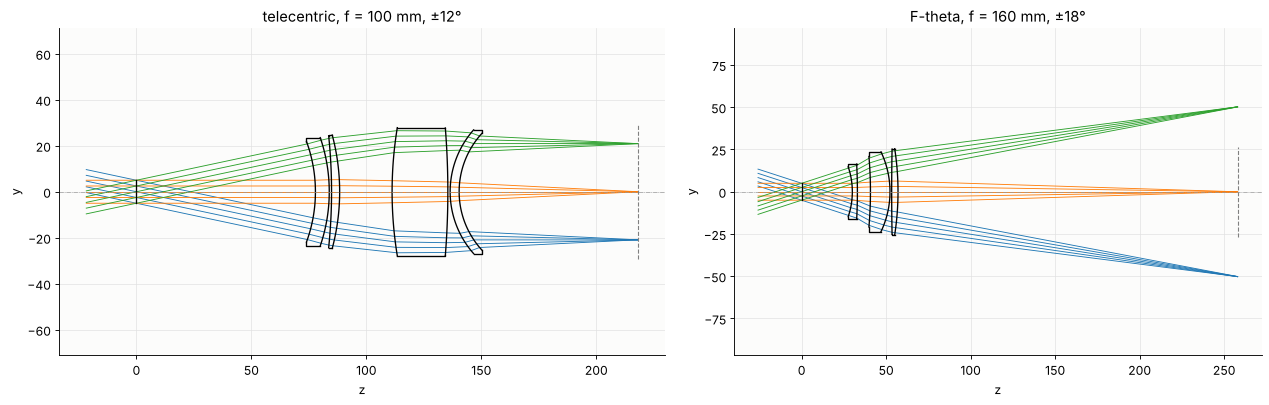

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
for ax, s, title, field in [(axes[0], telecentric_lens, "telecentric, f = 100 mm, ±12°", FIELD_TC),
                            (axes[1], ftheta_lens, "F-theta, f = 160 mm, ±18°", FIELD_FT)]:
    s.draw(ax, fields=[-field, 0.0, field], n_rays=5)
    ax.set_title(title)
    ax.set_aspect("equal")
fig.tight_layout()

The telecentric lens keeps its chief rays within half an arc minute of the
axis and still obeys the F-theta law within 7 µm (both can hold at once:
telecentricity is a statement about the pupil, $f\theta$ about the chief
ray heights). The spot shift for 1 mm of defocus at the edge of the field
falls from 159 µm to 0.1 µm. Its price: the beam fills the last lens to
26 mm from the axis, a lens of more than 52 mm diameter for a 42 mm
field, and a scanner 78 mm away from the lens, where the F-theta lens
covers a 100 mm field with lenses of about 50 mm, 30 mm behind the
scanner.

telecentric: spot RMS 5.2 to 17.3 um, wavefront 0.172 waves max, chief rays within 0.5 arcmin, |h - f theta| < 6.5 um
field ±20.9 mm; the beam at full field fills the last lens up to 25.6 mm from the axis
workpiece 1 mm out of focus at the field edge: the spot moves by 159 um (F-theta) and 0.1 um (telecentric)


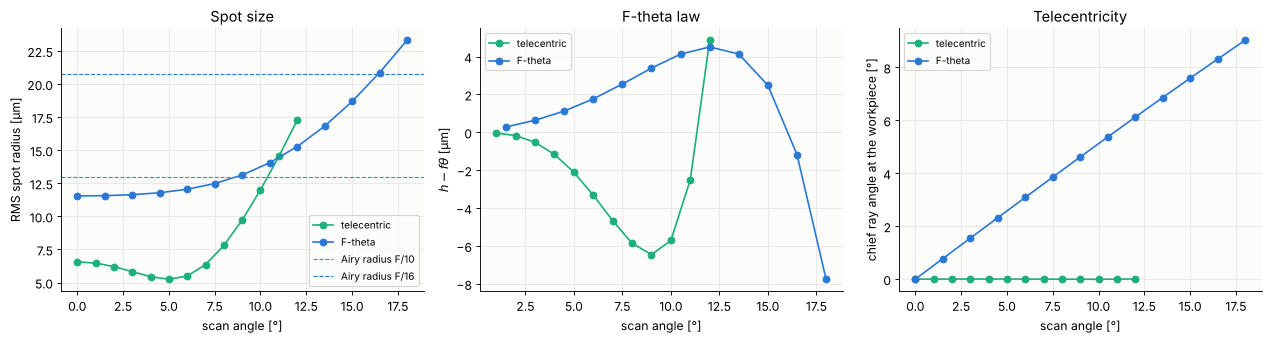

In [8]:
th_tc = np.linspace(0, 1, 13)*FIELD_TC
rms_tc, opd_tc = field_curves(telecentric_lens, th_tc)
airy_tc = 1.22*WL*F_TC/D_BEAM
tele_tc = sl.image_telecentricity(telecentric_lens, th_tc)
tele_ft = sl.image_telecentricity(ftheta_lens, th)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
axes[0].plot(np.degrees(th_tc), rms_tc*1e3, "o-", color=GREEN, label="telecentric")
axes[0].plot(np.degrees(th), rms_ft*1e3, "o-", color=BLUE, label="F-theta")
axes[0].axhline(airy_tc*1e3, color=GREEN, ls="--", lw=1, label="Airy radius F/10")
axes[0].axhline(airy*1e3, color=BLUE, ls="--", lw=1, label="Airy radius F/16")
axes[0].set_ylabel("RMS spot radius [µm]")
axes[0].legend(fontsize=9)
axes[0].set_title("Spot size")
axes[1].plot(np.degrees(th_tc[1:]), sl.ftheta_error(telecentric_lens, th_tc[1:], F_TC)*1e3, "o-",
             color=GREEN, label="telecentric")
axes[1].plot(np.degrees(th[1:]), err_ft*1e3, "o-", color=BLUE, label="F-theta")
axes[1].set_ylabel(r"$h - f\theta$ [µm]")
axes[1].set_title("F-theta law")
axes[1].legend(fontsize=9)
axes[2].plot(np.degrees(th_tc), np.degrees(tele_tc), "o-", color=GREEN, label="telecentric")
axes[2].plot(np.degrees(th), np.degrees(tele_ft), "o-", color=BLUE, label="F-theta")
axes[2].set_ylabel("chief ray angle at the workpiece [°]")
axes[2].set_title("Telecentricity")
axes[2].legend(fontsize=9)
for ax in axes:
    ax.set_xlabel("scan angle [°]")
fig.tight_layout()
print(f"telecentric: spot RMS {rms_tc.min()*1e3:.1f} to {rms_tc.max()*1e3:.1f} um, wavefront "
      f"{opd_tc.max():.3f} waves max, chief rays within {np.degrees(np.max(np.abs(tele_tc)))*60:.1f} "
      f"arcmin, |h - f theta| < {np.max(np.abs(sl.ftheta_error(telecentric_lens, th_tc[1:], F_TC)))*1e3:.1f} um")
last = telecentric_lens.surfaces[7]
hits = telecentric_lens.trace(telecentric_lens.rays(FIELD_TC, 0.0, [-1.0, 1.0]), clip=False)
print(f"field ±{F_TC*FIELD_TC:.1f} mm; the beam at full field fills the last lens up to "
      f"{np.max(np.abs(hits.points[8, :, 1])):.1f} mm from the axis")
dz = 1.0
print(f"workpiece 1 mm out of focus at the field edge: the spot moves by "
      f"{dz*np.tan(tele_ft[-1])*1e3:.0f} um (F-theta) and {dz*np.tan(tele_tc[-1])*1e3:.1f} um (telecentric)")

## 4. Two galvos in front of the lens: the bow of the scan lines

A real XY scanner has two mirrors, the x mirror first, the y mirror 15 mm
further along the beam (for a 10 mm beam), and the lens can only have its
pupil at one point. `scan_lenses.galvo_spots()` traces the beam that
`lidar.galvo_beam()` sends out of the scanner (the geometry of
`galvo_xy()` in notebook [132 (beam scanning)](132_beam_scanning.ipynb))
through the lens; the pupil plane lies half way between the mirrors
(`pupil=0.5`, unfolded along the beam), the mechanical angles span ±9°
(±18° optical).

The scan lines of constant mirror angle are not the straight lines of the
linear law $(x, y) = f\cdot(2\theta_x, -2\theta_y)$: lines of constant x
mirror angle bow outwards (pincushion in x), lines of constant y mirror
angle inwards (barrel in y), by up to 1.9 mm in the corners.

largest deviation from the linear law: 1909 um (corners)
corner spot for a mirror spacing of
     0 mm, pupil 0.0: (50.985, -48.489) mm
     0 mm, pupil 0.5: (50.985, -48.489) mm
     0 mm, pupil 1.0: (50.985, -48.489) mm
    15 mm, pupil 0.0: (50.930, -48.422) mm
    15 mm, pupil 0.5: (50.965, -48.489) mm
    15 mm, pupil 1.0: (50.938, -48.513) mm
    30 mm, pupil 0.0: (50.839, -48.333) mm
    30 mm, pupil 0.5: (50.898, -48.493) mm
    30 mm, pupil 1.0: (50.677, -48.513) mm
edge centres: x = 50.260 mm, y = -50.229 mm (f·2θ = 50.265 mm)


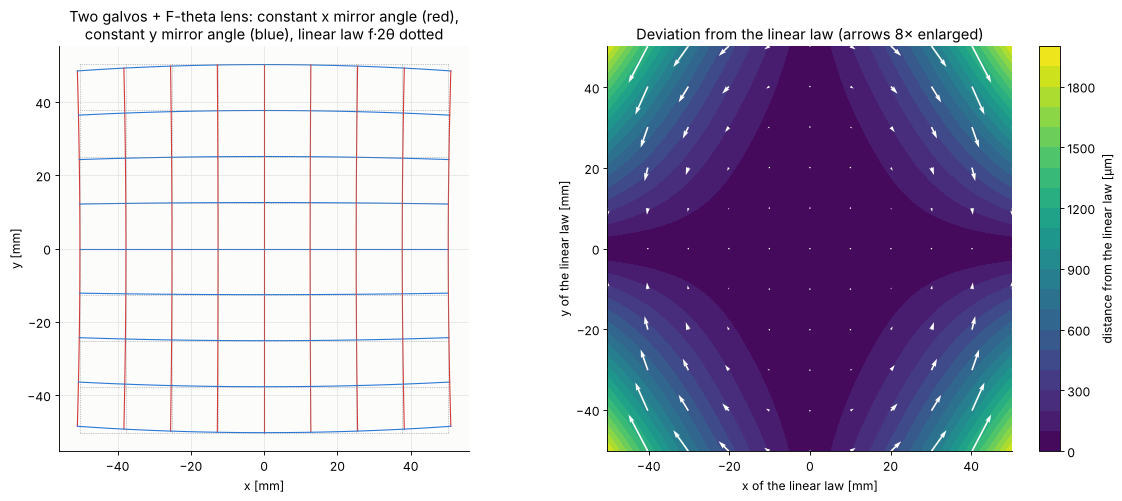

In [9]:
SEP = 15.0                      # mm between the mirrors along the beam
MECH_FT = FIELD_FT/2            # mechanical half angle
tm = np.linspace(-MECH_FT, MECH_FT, 9)
fine = np.linspace(-MECH_FT, MECH_FT, 61)


def galvo_ft(a, b, sep=SEP, pupil=0.5):
    return sl.galvo_spots(ftheta_lens, a, b, sep, pupil=pupil)[:2]


def linear_law(a, b, f):
    """Spot positions of the linear control law: optical angle 2*theta
    times f (the y mirror turns the beam towards -y)."""
    a, b = np.broadcast_arrays(a, b)
    return 2*f*a, -2*f*b


fig, axes = plt.subplots(1, 2, figsize=(15, 6.4))
ax = axes[0]
for t in tm:
    x, y = galvo_ft(np.full_like(fine, t), fine)
    ax.plot(x, y, color=RED, lw=1)
    x, y = galvo_ft(fine, np.full_like(fine, t))
    ax.plot(x, y, color=BLUE, lw=1)
    xl, yl = linear_law(t, fine, F)
    ax.plot(xl, yl, color=GREY, lw=0.6, ls=":")
    xl, yl = linear_law(fine, t, F)
    ax.plot(xl, yl, color=GREY, lw=0.6, ls=":")
ax.set_aspect("equal")
ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.set_title("Two galvos + F-theta lens: constant x mirror angle (red),\n"
             "constant y mirror angle (blue), linear law f·2θ dotted")
ax = axes[1]
A, B = np.meshgrid(fine, fine, indexing="ij")
X, Y = galvo_ft(A, B)
XL, YL = linear_law(A, B, F)
dev = np.hypot(X - XL, Y - YL)
cs = ax.contourf(XL, YL, dev*1e3, levels=20, cmap="viridis")
fig.colorbar(cs, ax=ax, label="distance from the linear law [µm]")
sk = slice(None, None, 6)
ax.quiver(XL[sk, sk], YL[sk, sk], (X - XL)[sk, sk], (Y - YL)[sk, sk], color="white",
          angles="xy", scale=1/8, scale_units="xy", width=0.004)
ax.set_aspect("equal")
ax.set_xlabel("x of the linear law [mm]")
ax.set_ylabel("y of the linear law [mm]")
ax.set_title("Deviation from the linear law (arrows 8× enlarged)")
ax.grid(False)
fig.tight_layout()
print(f"largest deviation from the linear law: {dev.max()*1e3:.0f} um (corners)")
corner = np.array([MECH_FT]), np.array([MECH_FT])
print("corner spot for a mirror spacing of")
for sep in (0.0, 15.0, 30.0):
    for pupil in (0.0, 0.5, 1.0):
        x, y = galvo_ft(*corner, sep=sep, pupil=pupil)
        print(f"  {sep:4.0f} mm, pupil {pupil:.1f}: ({x[0]:.3f}, {y[0]:.3f}) mm")
x, y = galvo_ft(np.array([MECH_FT, 0.0]), np.array([0.0, MECH_FT]))
print(f"edge centres: x = {x[0]:.3f} mm, y = {y[1]:.3f} mm (f·2θ = {2*F*MECH_FT:.3f} mm)")

The corner positions show where the bow comes from: it hardly depends on
the mirror spacing or on the position of the pupil (20 µm for the 15 mm
spacing with the pupil half way, up to 0.3 mm for 30 mm with the pupil at
the y mirror). It is the geometry of the two rotations: the y mirror turns a
beam that the x mirror has already tilted out of the plane of the y
rotation, so the beam sweeps a cone, not a plane. Its direction cosines
are about $(\sin\alpha, \cos\alpha\sin\beta, \cos\alpha\cos\beta)$ with
the optical angles α = 2θx, β = 2θy, and an F-theta lens maps the polar
angle Θ of this direction to the radius fΘ. Along the edge x line Θ grows
with β faster than α alone, $x = f\alpha\,(\Theta/\sin\Theta)(\sin\alpha/\alpha)$
grows: pincushion. On the edge y line the factor $\cos\alpha$ shrinks y:
barrel. The same bow appears without a lens in notebook
[132 (beam scanning)](132_beam_scanning.ipynb), where the field is a
plane at a fixed distance.

## 5. Telecentricity with two mirrors: where to put the pupil

For the telecentric lens the pupil position matters. Only a mirror in the
front focal plane makes its scan telecentric. A mirror a distance d away
from it tilts the beam at the workpiece by about $h\,d/f^2$ at the image
height h. With the pupil at the x mirror (left) the x scan is telecentric
and the y mirror, 15 mm away, tilts the beam by up to 1.8° at the edge of
the y scan; with the pupil at the y mirror (right) it is the other way
round. Half way (centre) both mirrors are 7.5 mm away, 0.9° per axis and
1.3° in the corners: the usual compromise, rotationally symmetric. Truly
telecentric two-axis scanning needs a relay between the mirrors (a 4f
system that images one onto the other) or a single two-axis mirror.

(The white corners are outside the ±6° mechanical scan.)

estimate: field height h, pivot a distance d from the front focal plane: angle h*d/f**2 = 0.90 deg for d = 7.5 mm, 1.80 deg for d = 15 mm


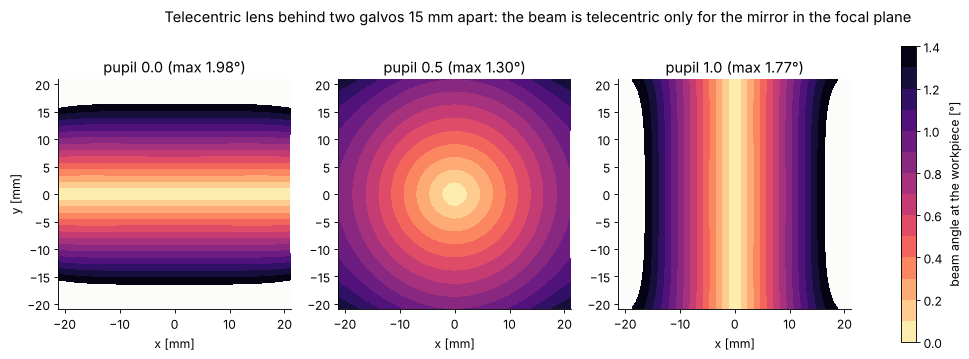

In [10]:
MECH_TC = FIELD_TC/2
tt = np.linspace(-MECH_TC, MECH_TC, 41)
A, B = np.meshgrid(tt, tt, indexing="ij")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, pupil in zip(axes, (0.0, 0.5, 1.0)):
    X, Y, Dout = sl.galvo_spots(telecentric_lens, A, B, SEP, pupil=pupil)
    ang = np.degrees(np.arctan2(np.hypot(Dout[..., 0], Dout[..., 1]), Dout[..., 2]))
    cs = ax.contourf(X, Y, ang, levels=np.linspace(0, 1.4, 15), cmap="magma_r")
    ax.set_aspect("equal")
    ax.set_title(f"pupil {pupil:.1f} (max {ang.max():.2f}°)")
    ax.set_xlabel("x [mm]")
    ax.grid(False)
axes[0].set_ylabel("y [mm]")
fig.colorbar(cs, ax=axes, label="beam angle at the workpiece [°]")
fig.suptitle("Telecentric lens behind two galvos 15 mm apart: the beam is telecentric only "
             "for the mirror in the focal plane")
print(f"estimate: field height h, pivot a distance d from the front focal plane: angle h*d/f**2 = "
      f"{np.degrees(F_TC*FIELD_TC*SEP/2/F_TC**2):.2f} deg for d = {SEP/2:.1f} mm, "
      f"{np.degrees(F_TC*FIELD_TC*SEP/F_TC**2):.2f} deg for d = {SEP:.0f} mm")

## 6. Correction by a lookup table

Scanner controllers take spot positions, not mirror angles: a lookup table
holds the mirror angles for a grid of positions on the workpiece, measured
on a calibration plate or computed from the design, and the controller
interpolates between the nodes. `scan_lenses.invert_scan()` finds the
angles for given positions by Newton's method on the traced spots (a
finite difference 2 × 2 Jacobian); `CorrectionTable` does that on a grid of
nodes and interpolates bilinearly or with a bicubic spline.

The error of the linear law, 1.8 mm in the corners and 0.47 mm RMS,
falls to 34 µm with a 9 × 9 table and bilinear interpolation; the error is
largest between the nodes, where the bow is curved. Bilinear interpolation
converges as $1/n^2$ with the number n of nodes per axis, bicubic as
$1/n^4$: 9 × 9 bicubic nodes give 1 µm, a tenth of the spot radius,
which bilinear interpolation reaches only with a 65 × 65 table (the size
of common controller tables). The table also absorbs the residual F-theta
error of the lens and, measured, the mounting errors of the head.

linear law without correction: max 1793 um, rms 472 um
 5 x  5 table, linear: max  118.213 um
 5 x  5 table, cubic : max   10.093 um
 9 x  9 table, linear: max   34.349 um
 9 x  9 table, cubic : max    1.125 um
17 x 17 table, linear: max    9.363 um
17 x 17 table, cubic : max    0.099 um
33 x 33 table, linear: max    2.486 um
33 x 33 table, cubic : max    0.008 um
65 x 65 table, linear: max    0.591 um
65 x 65 table, cubic : max    0.000 um


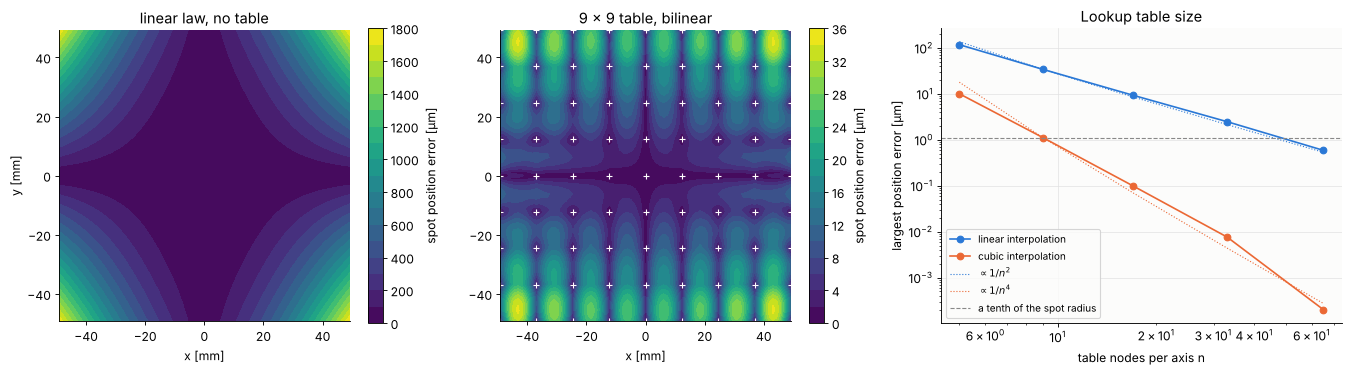

In [11]:
def spots_ft(a, b):
    return galvo_ft(a, b)


H = 2*F*MECH_FT*0.98          # usable square field (corners inside the scan)
q = np.linspace(-H, H, 81)
QX, QY = np.meshgrid(q, q, indexing="ij")


def residual(ax_, ay_):
    x, y = spots_ft(ax_, ay_)
    return np.hypot(x - QX, y - QY)


r_lin = residual(QX/(2*F), -QY/(2*F))
results = {}
for n in (5, 9, 17, 33, 65):
    nodes = np.linspace(-H, H, n)
    for method in ("linear", "cubic"):
        table = sl.CorrectionTable(spots_ft, nodes, nodes, method=method)
        results[(n, method)] = residual(*table(QX, QY))
print(f"linear law without correction: max {r_lin.max()*1e3:.0f} um, rms "
      f"{np.sqrt(np.mean(r_lin**2))*1e3:.0f} um")
for (n, method), r in results.items():
    print(f"{n:2d} x {n:2d} table, {method:6s}: max {r.max()*1e3:8.3f} um")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, r, title in [(axes[0], r_lin, "linear law, no table"),
                     (axes[1], results[(9, "linear")], "9 × 9 table, bilinear")]:
    cs = ax.contourf(QX, QY, r*1e3, levels=20, cmap="viridis")
    fig.colorbar(cs, ax=ax, label="spot position error [µm]")
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("x [mm]")
    ax.grid(False)
axes[0].set_ylabel("y [mm]")
nodes9 = np.linspace(-H, H, 9)
N9X, N9Y = np.meshgrid(nodes9, nodes9)
axes[1].plot(N9X, N9Y, "w+", ms=6)
ax = axes[2]
ns = np.array([5, 9, 17, 33, 65])
for method, col in [("linear", BLUE), ("cubic", ORANGE)]:
    ax.loglog(ns, [results[(n, method)].max()*1e3 for n in ns], "o-", color=col,
              label=f"{method} interpolation")
ax.loglog(ns, results[(9, "linear")].max()*1e3*(8/(ns - 1))**2, ":", color=BLUE, lw=1,
          label=r"$\propto 1/n^2$")
ax.loglog(ns, results[(9, "cubic")].max()*1e3*(8/(ns - 1))**4, ":", color=ORANGE, lw=1,
          label=r"$\propto 1/n^4$")
ax.axhline(w0*1e3/10, color=GREY, ls="--", lw=1, label="a tenth of the spot radius")
ax.set_xlabel("table nodes per axis n")
ax.set_ylabel("largest position error [µm]")
ax.set_title("Lookup table size")
ax.legend(fontsize=9)
fig.tight_layout()

## Summary

- An F-theta lens trades the $f\tan\theta$ of a well corrected lens for
  $f\theta$, a barrel distortion of 3.3 % at 18°, so that the spot moves
  linearly with the mirror angle. A strong negative meniscus in front of
  two positive lenses, optimized with DLS for spot size and the F-theta
  law (`lo.ftheta()`), gives f = 160 mm and ±18° for a 10 mm beam at
  1064 nm, diffraction limited to 10.5°, spots within the Airy radius
  to 16° and $|h - f\theta| < 8$ µm.
- A telecentric scan lens puts the scanner in its front focal plane: the
  beam meets the workpiece normally (spot shift with defocus 0.1 µm
  instead of 160 µm per mm), at the cost of a last lens as large as the
  field. One more operand (`lo.image_telecentricity()`) and the scanner
  distance as a variable make it from the same recipe.
- An XY galvo scanner bows the scan lines by up to 1.9 mm in the
  corners of a 100 mm field, from the geometry of the two rotations
  rather than from the mirror spacing; the spacing does break telecentricity, by $h\,d/f^2$ per mirror.
- A lookup table of mirror angles over a grid of positions removes the
  bow; bicubic interpolation needs far fewer nodes than bilinear.

## References

- W. J. Smith, *Modern Lens Design*, 2nd ed., McGraw-Hill (2005),
  chapter on scanner lenses.
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008).
- G. F. Marshall and G. E. Stutz (eds.), *Handbook of Optical and Laser
  Scanning*, 2nd ed., CRC Press (2011), chapters on scan lenses and on
  galvanometric scanners (J. Montagu).
- L. Beiser, *Unified Optical Scanning Technology*, Wiley (2003).
- C. G. Wynne and P. M. J. H. Wormell, "Lens design by computer", Appl.
  Opt. 2, 1233-1238 (1963).

In [12]:
print(f"run time {time.time() - t_start:.0f} s")

run time 50 s
